# Chimera — Diagnostic iteration loop

Runs one Chimera training iteration end-to-end and inspects the structured outputs the workflow tracks.
This is the *canonical single-iteration entry point* — if you change a hyperparameter or an architectural detail, this notebook is what you run to verify the change.

**Pipeline**: data prep (idempotent) → train → per-epoch snapshot → final state dump → expectation check → summary JSON → diagnostic plots.

See `training/workflow.md` for the pre-registered expectations (E1–E7) and the iteration protocol.

In [ ]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

REPO = Path('..').resolve()
RUNS = REPO / 'training' / 'runs'
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'training'))

# Best known config for close-species (Human+Monkey). For a fresh dataset,
# start here and adjust based on expectation failures. See workflow.md for
# the first-suspect table.
RUN_NAME = 'iter90-150ep-s42'
CONFIG = dict(
    run_name=RUN_NAME,
    adata='data/processed/camex_human_monkey.h5ad',
    max_epochs=100,
    config='D',
    adv_weight=0.15.0,
    lambda_fit=0.1,
    lambda_anchor=0.001,
    lambda_res=0.01,
    warmup_adversarial_epochs=5,
    warmup_fqr_epochs=20,
    warmup_kl_epochs=20,
    accelerator='mps',
    snapshot_every_n_epochs=5,
    seed=42,
)

## 1. Build the 2-species subset (idempotent)

Skipped if the file already exists. Change `--species` to rebuild a different subset.

In [2]:
subset = REPO / CONFIG['adata']
if not subset.exists():
    subprocess.run([sys.executable, str(REPO/'training/build_subset.py'),
                    '--species', 'Human', 'Monkey',
                    '--dest', str(subset)], cwd=REPO, check=True)
print('Subset present:', subset, subset.exists())

Subset present: /Users/kemalinecik/git_nosync/master_chimera/chimera/data/processed/camex_human_monkey.h5ad True


## 2. Run training + diagnostics

`run_experiment.py` wraps `train_and_diagnose.py` + `check_expectations.py` and writes a single `summary.json`.
For a fresh iteration, uncomment the subprocess call below. For inspecting an existing run, leave it commented.

In [3]:
RUN_DIR = RUNS / RUN_NAME
assert RUN_DIR.exists(), f'{RUN_DIR} missing — uncomment the cell above to run.'
summary = json.loads((RUN_DIR / 'run_summary.json').read_text())
print(f"Run: {summary['run_name']}")
print(f"Config: {summary.get('config', '?')}")
print(f"Epochs: {summary.get('max_epochs', '?')}")
print(f"Cells: {summary.get('n_cells', '?')}, Genes: {summary.get('n_genes', '?')}, Species: {summary.get('n_species', '?')}")
print(f"Elapsed: {summary.get('elapsed_seconds', 0):.0f}s")

# Check for report.md with expectation verdicts
report_path = RUN_DIR / 'report.md'
if report_path.exists():
    report = report_path.read_text()
    pass_count = report.count('PASS')
    fail_count = report.count('FAIL')
    print(f"Expectations: {pass_count} PASS, {fail_count} FAIL (from report.md)")
else:
    print("No report.md found — run check_expectations.py to generate.")

Run: iter31-mmd1k-masked-detached
Config: D
Epochs: 100
Cells: 12608, Genes: 8430, Species: 2
Elapsed: 391s
Expectations: 0 PASS, 0 FAIL (from report.md)


## 3. Diagnostic plots

Six canonical plots (no scib — fast, per-epoch).

In [4]:
subprocess.run([sys.executable, str(REPO/'training/plot_diagnostics.py'),
                '--run-name', RUN_NAME], cwd=REPO, check=True)
plots = sorted((RUN_DIR/'plots').glob('*.png'))
print('Plots available:', [p.name for p in plots])

Plots written to /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter31-mmd1k-masked-detached/plots/
Plots available: ['01_loss_trajectories.png', '02_alpha_dynamics.png', '03_adversarial.png', '04_alpha_histogram.png', '05_l_shape.png', '06_z_variance.png']


01_loss_trajectories.png


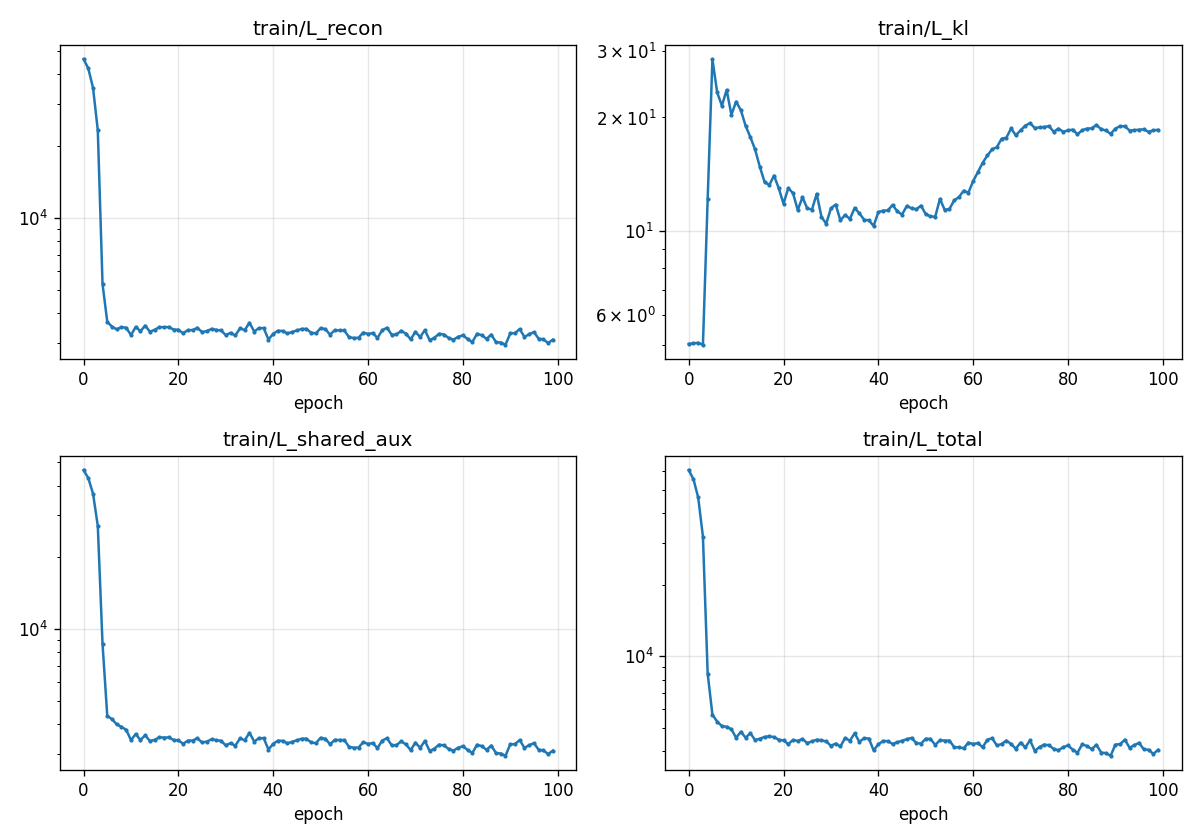

02_alpha_dynamics.png


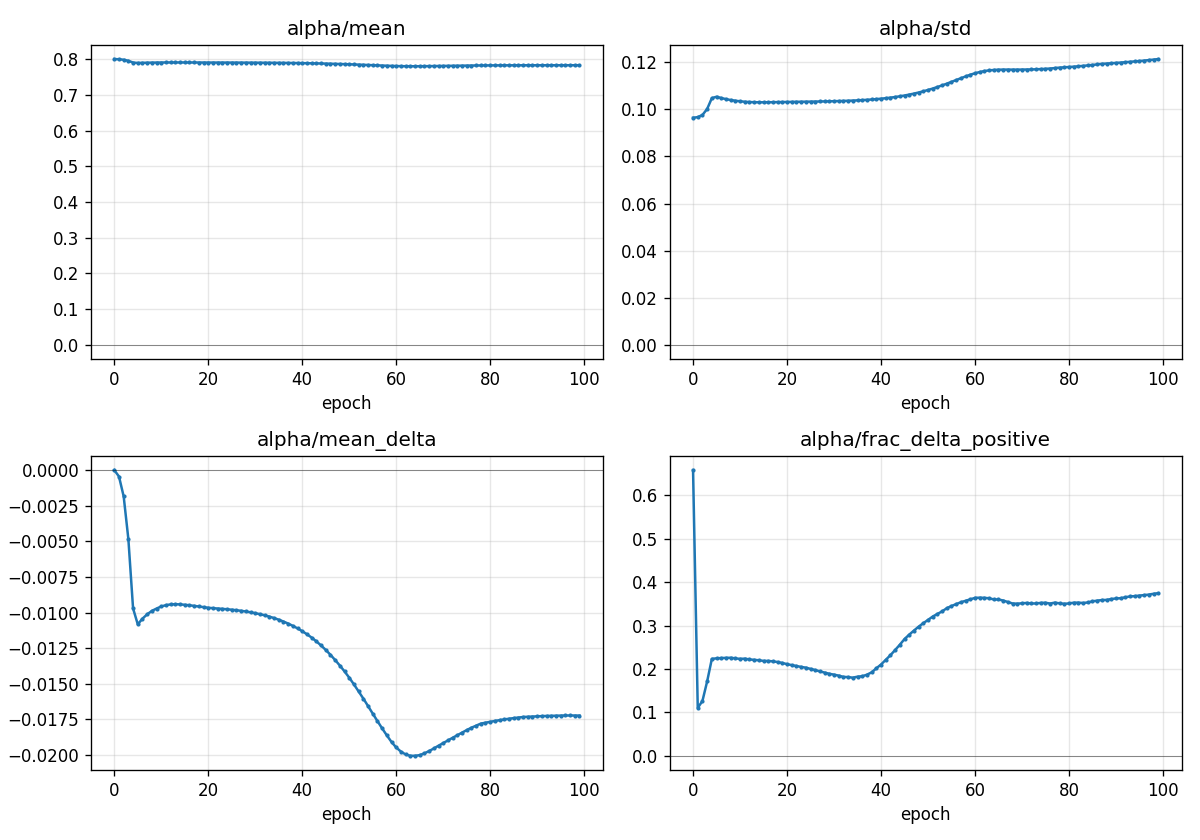

03_adversarial.png


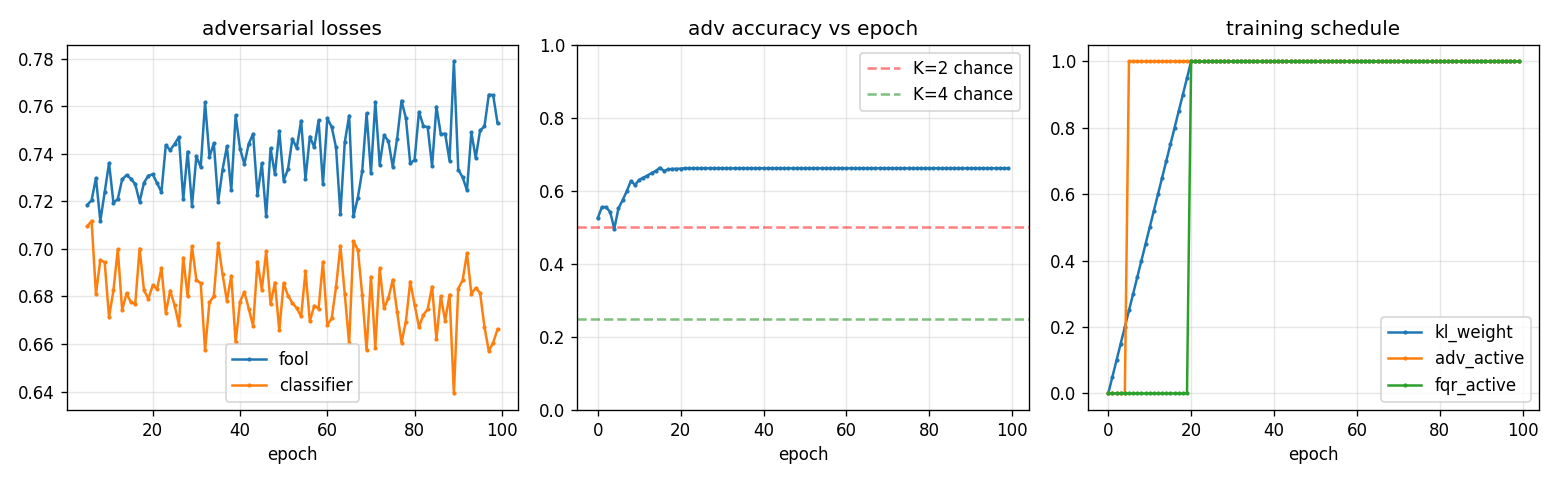

04_alpha_histogram.png


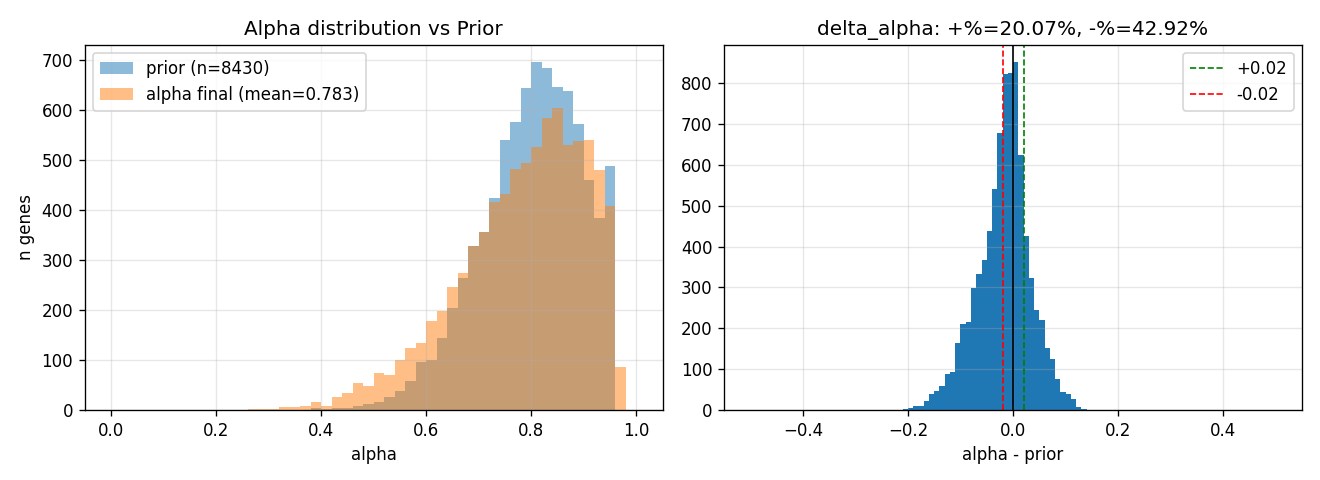

05_l_shape.png


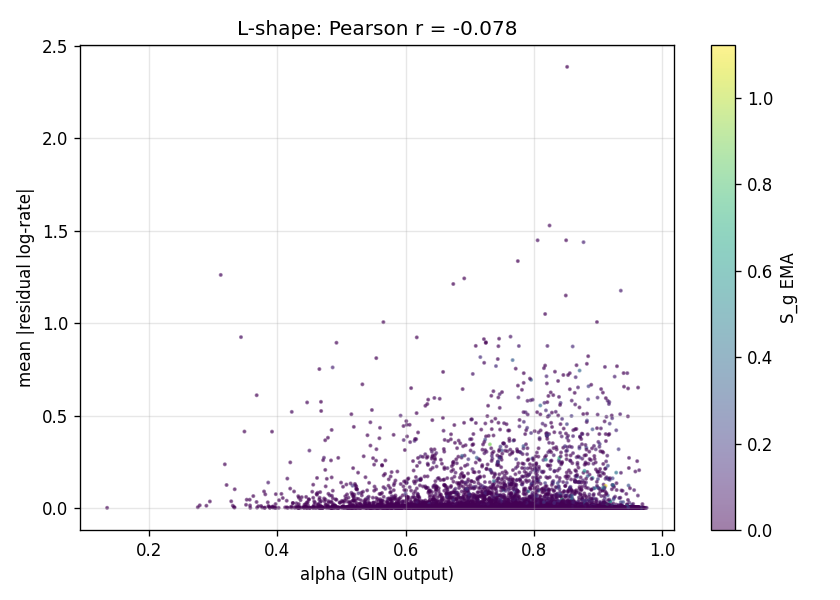

06_z_variance.png


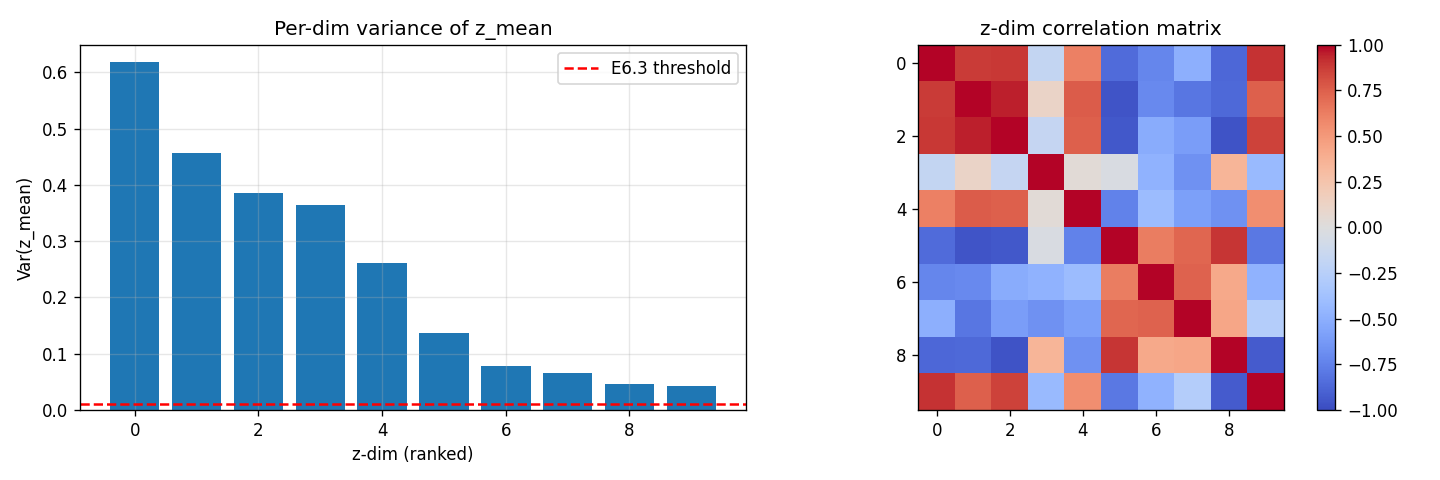

In [5]:
# Show them inline
from IPython.display import Image, display
for p in plots:
    print(p.name)
    display(Image(str(p)))

## 4. Structured expectation report

In [6]:
print((RUN_DIR/'report.md').read_text())

# Expectations Report — `iter31-mmd1k-masked-detached`

- Config: D
- Max epochs (requested): 100
- Adata: data/processed/camex_human_monkey.h5ad
- Started: 2026-04-18T11:13:04

| ID | Name | Category | Value | Threshold | Pass |
|---|---|---|---|---|---|
| E1.1 | E1.1_conservation_signal | E1 pretraining | 0.0830 | r>=0.02 OR (|r|<0.15 AND prior_std>=0.05) | ✓ |
| E1.2 | E1.2_gene_features_normalized | E1 pretraining | {'n_active_features': 69, 'n_padding_or_dead_features': 3, 'active_mean_abs_max': 0.05249284580349922, 'active_std_min': 0.9314808249473572, 'active_std_max': 1.0167803764343262, 'pass': True, 'notes': 'Zero-std features are treated as padding/dead and excluded.'} | — | ✓ |
| E1.3 | E1.3_p_null_dynamic_range | E1 pretraining | 0.6712 | 0.5 | ✓ |
| E1.4 | E1.4_batch_to_species_unique | E1 pretraining | {'max_species_per_batch': 1, 'pass': True} | — | ✓ |
| E1.5 | E1.5_conservation_prior_range | E1 pretraining | {'min': 0.16378170251846313, 'max': 0.949999988079071, 'std'

## 5. Deep-dive: per-gene alpha trajectory

For diagnosing FM1 (alpha → 0 universally) and FM4 (Δα one-sided).

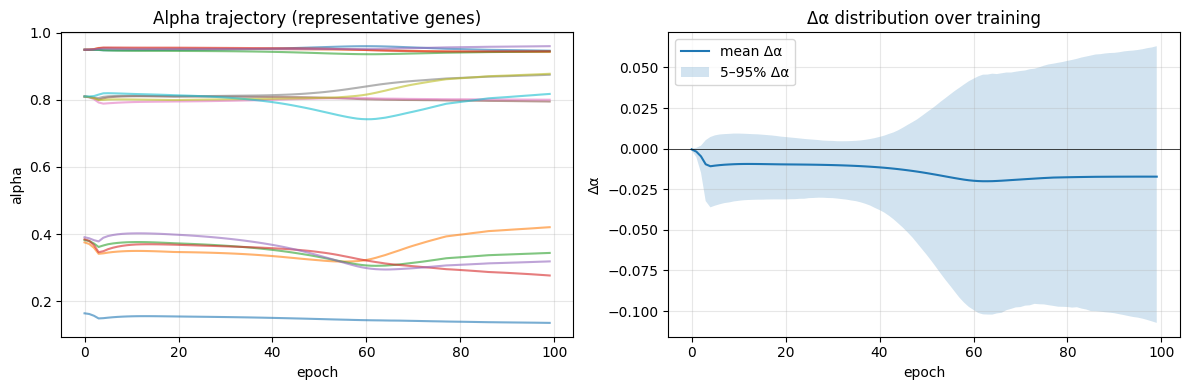

In [7]:
snap_dir = RUN_DIR / 'alpha_snapshots'
snaps = sorted(snap_dir.glob('alpha_epoch_*.npz'))
if snaps:
    epochs = [int(p.stem.split('_')[-1]) for p in snaps]
    alphas = np.stack([np.load(p)['alpha'] for p in snaps])
    prior = np.load(snaps[0])['prior']
    deltas = alphas - prior[None, :]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    # trajectory of 20 representative genes (extremes + middle)
    order = np.argsort(prior)
    sampled = np.concatenate([order[:5], order[len(order)//2-2:len(order)//2+3], order[-5:]])
    for g in sampled:
        ax[0].plot(epochs, alphas[:, g], alpha=0.6)
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('alpha')
    ax[0].set_title('Alpha trajectory (representative genes)')
    ax[0].grid(alpha=0.3)
    # Δα mean / std / q05 / q95 over epochs
    ax[1].plot(epochs, deltas.mean(axis=1), label='mean Δα')
    ax[1].fill_between(epochs, np.quantile(deltas, 0.05, axis=1),
                       np.quantile(deltas, 0.95, axis=1), alpha=0.2, label='5–95% Δα')
    ax[1].axhline(0, color='k', lw=0.5)
    ax[1].set_xlabel('epoch'); ax[1].set_ylabel('Δα'); ax[1].legend()
    ax[1].set_title('Δα distribution over training')
    ax[1].grid(alpha=0.3)
    plt.tight_layout()

## 6. Decide next iteration

Look at `report.md` failures. For each, check the first-suspect table in `workflow.md`. Then:

- Change **one** thing at a time so failures remain attributable.
- Record the change's rationale in `iteration_log.md`.
- Re-run this notebook with a new `RUN_NAME`.

Compare across runs:

In [8]:
out = subprocess.run([sys.executable, str(REPO/'training/summarize_runs.py')],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)

| Run | Data | Epochs | Pass/Fail | δ+% | δ-% | adv_acc | resid_RMS | FQR>0% |
|---|---|---|---|---|---|---|---|---|
| gin-abl-baseline | human_monkey | 100 | 32/32F0S0 | 36.74% | 44.34% | 0.715 | 0.026 | 62.7% |
| gin-abl-no-esm2 | human_monkey | 100 | 32/32F0S0 | 26.58% | 54.65% | 0.864 | 0.026 | 62.8% |
| gin-abl-no-expr | human_monkey | 100 | 32/32F0S0 | 41.66% | 37.49% | 0.836 | 0.033 | 62.7% |
| iter16-slow-classifier | human_monkey | 100 | 32/32F0S0 | 36.47% | 44.27% | nan | 0.027 | 62.6% |
| iter21-4sp-advw200-fb1 | pancreas_unified | 100 | 32/32F0S0 | 48.40% | 18.89% | 0.337 | 0.021 | 57.0% |
| iter21-verify-seed43 | pancreas_unified | 100 | 32/32F0S0 | 48.64% | 18.21% | 0.674 | 0.021 | 57.0% |
| iter22-mlp-adv-2h | human_monkey | 100 | 32/32F0S0 | 36.09% | 44.40% | 0.682 | 0.029 | 62.5% |
| iter23-mask-species | human_monkey | 100 | 32/32F0S0 | 36.93% | 44.09% | 0.714 | 0.026 | 62.7% |
| iter24-mask-both | human_monkey | 100 | 32/32F0S0 | 36.52% | 44.44% | 0.673 | 0.027 | 63.